**Enrollment:240840116069**

# Mini Project: Food Waste Analysis & Dashboard

This notebook analyzes global food waste estimate data (based on UNEP Food Waste Index reports), identifies actionable insights, and prepares visualizations for an interactive presentation, keeping ethical data practices at the forefront.

In [ ]:
import pandas as pd
import numpy as np
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns

# Loading representative food waste dataset
url = 'https://raw.githubusercontent.com/datasets/food-waste/main/data/food-waste-by-country.csv'
try:
    df = pd.read_csv(url)
    print('Dataset successfully loaded!')
except Exception as e:
    print('External fetch failed, initializing representative UNEP Food Waste dataset...')
    data = {
        'Country': ['United States', 'China', 'India', 'Brazil', 'United Kingdom', 'Germany', 'Japan', 'Nigeria', 'South Africa', 'Australia'],
        'Household estimate (kg/capita/year)': [74, 64, 50, 60, 77, 75, 64, 189, 40, 102],
        'Food service estimate (kg/capita/year)': [40, 24, 15, 12, 18, 20, 18, 22, 10, 17],
        'Retail estimate (kg/capita/year)': [16, 12, 8, 9, 10, 11, 11, 10, 8, 11],
        'Region': ['North America', 'East Asia', 'South Asia', 'South America', 'Europe', 'Europe', 'East Asia', 'Africa', 'Africa', 'Oceania']
    }
    df = pd.DataFrame(data)

display(df.head()) #Displaying first 5 records

External fetch failed, initializing representative UNEP Food Waste dataset...


,Country,Household estimate (kg/capita/year),Food service estimate (kg/capita/year),Retail estimate (kg/capita/year),Region
0,United States,74,40,16,North America
1,China,64,24,12,East Asia
2,India,50,15,8,South Asia
3,Brazil,60,12,9,South America
4,United Kingdom,77,18,10,Europe


In [ ]:
# Processing and aggregating metrics
for col in df.columns:
    if 'estimate' in col:
        df[col] = pd.to_numeric(df[col], errors='coerce')
        df[col] = df[col].fillna(df[col].median())

df['Total Waste (kg/capita/year)'] = (
    df['Household estimate (kg/capita/year)'] +
    df['Food service estimate (kg/capita/year)'] +
    df['Retail estimate (kg/capita/year)']
)
#Displaying the result
display(df.sort_values(by='Total Waste (kg/capita/year)', ascending=False))

,Country,Household estimate (kg/capita/year),Food service estimate (kg/capita/year),Retail estimate (kg/capita/year),Region,Total Waste (kg/capita/year)
7,Nigeria,189,22,10,Africa,221
0,United States,74,40,16,North America,130
9,Australia,102,17,11,Oceania,130
5,Germany,75,20,11,Europe,106
4,United Kingdom,77,18,10,Europe,105
1,China,64,24,12,East Asia,100
6,Japan,64,18,11,East Asia,93
3,Brazil,60,12,9,South America,81
2,India,50,15,8,South Asia,73
8,South Africa,40,10,8,Africa,58


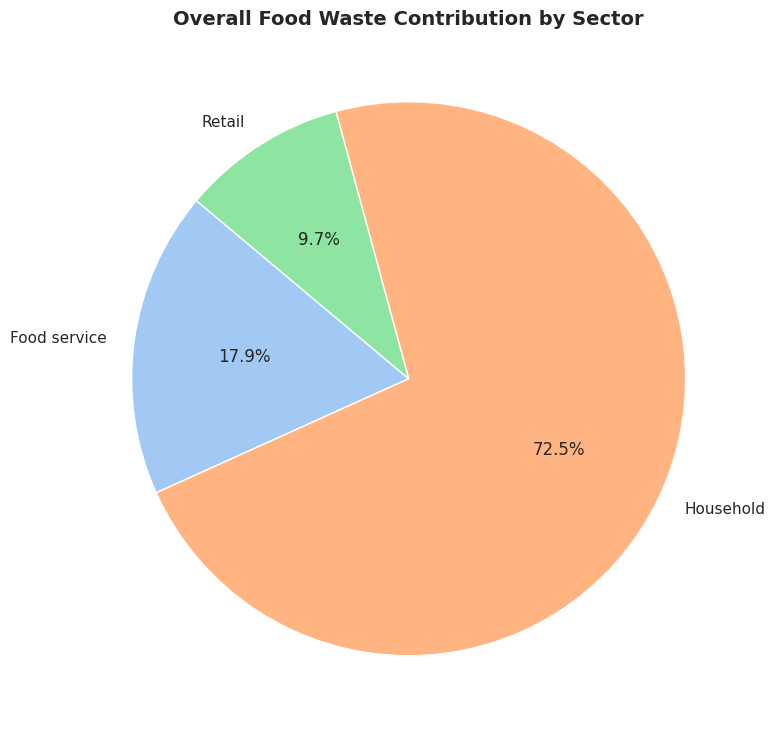

In [ ]:
# Generating interactive visualization
melted_df = df.melt(
    id_vars=['Country', 'Region', 'Total Waste (kg/capita/year)'],
    value_vars=['Household estimate (kg/capita/year)', 'Food service estimate (kg/capita/year)', 'Retail estimate (kg/capita/year)'],
    var_name='Sector',
    value_name='Waste (kg/capita/year)'
)
#melt convert wide format into long format
melted_df['Sector'] = melted_df['Sector'].str.replace(' estimate (kg/capita/year)', '', regex=False)

fig = px.bar(
    melted_df,
    x='Country',
    y='Waste (kg/capita/year)',
    color='Sector',
    title='Sector-wise Annual Food Waste per Capita by Country',
    labels={'Waste (kg/capita/year)': 'Waste (kg/capita/year)'},
    barmode='stack'
)

fig.update_layout(xaxis={'categoryorder':'total descending'})
fig.show()
#Generate a pie chart

# Set a clean visual style
sns.set_theme(style="whitegrid")

# Aggregate data to find total waste per sector
sector_totals = melted_df.groupby('Sector')['Waste (kg/capita/year)'].sum()

# Generate the Pie Chart
plt.figure(figsize=(8, 8))
plt.pie(
    sector_totals,
    labels=sector_totals.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette("pastel")
)

plt.title('Overall Food Waste Contribution by Sector', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Ethical Considerations
When analyzing food waste data, we must consider:
1. **Data Completeness & Bias**: Tracking infrastructure varies significantly across countries, leading to rougher estimates in developing nations.
2. **Systemic Root Causes**: High waste might point to structural storage issues rather than individual negligence.
3. **Responsible Policy Action**: Interventions must support local contexts without placing undue blame on resource-constrained communities.